# Tutorial: how to use `pangeo-fish`


**Overview.**

This Jupyter notebook demonstrates how to use `pangeo-fish`.

Specifically, we will fit the geolocation on the data from the study conducted by M. Gonze et al. titled "Combining acoustic telemetry with archival tagging to investigate the spatial dynamics of the understudied pollack *Pollachius pollachius*", accepted for publication in the Journal of Fish Biology.

We will use the biologging tag "A19124", which was attached to pollock fish.

As for the reference Earth Observation (EO) data, we consider the European Union Copernicus Marine Service Information (CMEMS) product "NORTHWESTSHELF_ANALYSIS_FORECAST_PHY_004_013".

_NB: In addition to the Data Storage Tag (DST), the biologging data includes **teledetection by acoustic signals**, as well as the release and recapture/death information of the fish._

Both the reference EO and the biologging data are publicly available, and the computations should be tractable for most standard laptops.

**Workflow.**

Let's first summarize the key steps for running the geolocation:

1. **Define the configuration:** define the required parameters for the analysis.
2. **Compare the reference data with the DST information:** compare the data from the reference model with the biologging data. 
3. **Regrid the comparison to HEALPix:** translate the comparison into a HEALPix grid to avoid spatial distortion.
4. **Construct the temporal emission matrix:** create a temporal emission probability distribution (_pdf_) from the transformed grid.
5. **Construct another emission matrix with the acoustic detections:** calculate a similar model to the previous one, using this time the acoustic teledetections.
6. **Combine and normalize the matrices:** merge and normalize the two _pdfs_.
7. **Estimate (or _fit_) the geolocation model:** determine the parameters of the model based on the normalized emission matrix.
8. **Compute the state probabilities and generate trajectories:** compute the fish's location probability distribution and generate subsequent trajectories.
9. **Visualization:** visualize the evolution of the spatial probabilities over time and export the video.

Throughout this tutorial, you will gain practical experience in setting up and executing a typical workflow using `pangeo-fish` such that you can then apply the tool with your use-case study.

## 1. Initialization and configuration definition

In this step, we prepare the execution of the analysis.
It includes:
- Installing the necessary packages.
- Importing the required libraries.
- Defining the parameters for the next stages of the workflow.
- Configuring the cluster for distributed computing.
    

Only if you don't have good GPU (>=7.5)

In [1]:
# do this
import torch
import os

os.environ["CUDA_VISIBLE_DEVICES"] = ""

### Mandatory libraries

In [2]:
from pint_xarray import unit_registry as ureg
import hvplot.xarray
import xarray as xr
import sys

# sys.path.append("../")
import pangeo_fish
from pangeo_fish.xarray_update import Accessor
from pangeo_fish.helpers import multiplot_healpix, multi_map_with_synced_sliders

/Users/todaka/micromamba/envs/pangeo-fish-venv/lib/python3.11/site-packages/movingpandas/__init__.py:41: UserWarning: Missing optional dependencies. To use the trajectory smoother classes please install Stone Soup (see https://stonesoup.readthedocs.io/en/latest/#installation).
  warnings.warn(e.msg, UserWarning)


### Parameters

In [8]:
# tag_name corresponds to the name of the biologging tag name (DST identification number),
# which is also a path for storing all the information for the specific fish tagged with tag_name.

tag_name = "A18828"  
tag_name = "A19124"  

# tag_root specifies the root URL for tag data used for this computation. You can check the present link to see other tags.
# You can also put a local path if you have a tag on your computer

tag_root = "https://data-taos.ifremer.fr/demo/tag/tag/"

copernicus_model_name = "cmems_mod_glo_phy_my_0.083deg_P1D-m"

# ref_url is the path to the reference model.
# When set to None, load_model fetches the CMEMS Global Ocean Physics
# Reanalysis (daily-mean, 1/12 deg, `cmems_mod_glo_phy_my_0.083deg_P1D-m`)
# directly via the copernicusmarine client.
# To use a different reference, pass a `.yaml` intake catalog or a
# `.parq` / `.json` kerchunk reference here.
ref_url = None

# scratch_root specifies the root directory for storing output files.
# storage_options specifies options for the filesystem storing output files.

## example for remote storage (you need gfts credentials for this one)
scratch_root = "s3://destine-gfts-data-lake/demo"
storage_options = {
    "anon": False,
    "profile": "gfts",
    "client_kwargs": {
        "endpoint_url": "https://s3.gra.perf.cloud.ovh.net",
        "region_name": "gra",
    },
}
## example for using your local file system instead
scratch_root = "./test"
storage_options = None

# Default chunk value for time dimension. This values depends on the configuration of your dask cluster.
chunk_time = 1  # 1 means that a chunk will contain one timestep. -1 will take all the time step in one chunk

# Either to use a HEALPix grid (["cells"]) or a 2D grid (["x", "y"])
dims = ["cells"]

# bbox, bounding box, defines the latitude and longitude range for the analysis area.
bbox = {"latitude": [46, 59], "longitude": [-14, 2]}
# relative_depth_threshold defines the acceptable fish depth relative to the maximum tag depth.
# It determines whether the fish can be considered to be in a certain location based on depth.
# If you are not using a bathy pdf (calculate later at choice) put 0.8 (hand made)
# it has to be between 0 and 1
relative_depth_threshold = 0

# refinement level  defines the resolution of the healpix grid used for regridding.
refinement_level = 10  # correspond to 12*2**10 cells

# min_vertices sets the minimum number of vertices for a valid transcription for regridding. It is for the use of
min_vertices = 1

# differences_std sets the standard deviation for scipy.stats.norm.pdf.
# It expresses the estimated certainty of the field of difference.
differences_std = 0.75  # in °C
# initial_std sets the covariance for initial event.
# It shows the certainty of the initial area.
initial_std = 1e-5  # hand made in radians
# recapture_std sets the covariance for recapture event.
# It shows the certainty of the final recapture area if it is known.
recapture_std = 1e-4
# earth_radius defines the radius of the Earth used for distance calculations.
earth_radius = ureg.Quantity(6371, "km")
# maximum_speed sets the maximum allowable speed for the tagged fish.
maximum_speed = ureg.Quantity(60, "km / day")
# adjustment_factor scales the upper bound of the sigma search done by optimize_pdf():
#   max_sigma = maximum_speed * time_step * adjustment_factor / earth_radius   (in radians)
# With 5, the search range (up to ~0.047 rad) contains a second, spurious minimum far from
# the physical one and the optimizer can stop there. With 1, sigma stays below the
# displacement allowed by maximum_speed (~0.0094 rad, i.e. 60 km per daily time step).
adjustment_factor = 1
# truncate sets the truncating factor for computed maximum allowed sigma for convolution process.
truncate = 4

# receiver_buffer sets the maximum allowed detection distance for acoustic receivers.
receiver_buffer = ureg.Quantity(1000, "m")


# tolerance describes the tolerance level of the search during the fitting/optimization of the geolocation.
# Smaller values will make the optimization iterate more
tolerance = 1e-6

# track_modes defines the modes for generating fish's trajectories.
track_modes = ["mean", "mode"]
# additional_track_quantities sets quantities to compute for tracks using moving pandas.
additional_track_quantities = ["speed", "distance"]


# time_step defines the time interval between each frame of the visualization
time_step = 3
# ellipsoid defines which model of the earth will be used: "sphere" is a sphere,
# "WGS84" is a ellipsoidal model with the parameter of the earth
ellipsoid = "sphere"

In [9]:
# Define target root directories for storing analysis results.
target_root = f"{scratch_root}/{tag_name}"

# Defines default chunk size for optimization.
default_chunk = {"time": chunk_time, "lat": -1, "lon": -1}
default_chunk_dims = {"time": chunk_time}
default_chunk_dims.update({d: -1 for d in dims})

### Dask
allows parallelisation and so faster calculs

In [10]:
# Set up a local cluster for distributed computing.
from distributed import LocalCluster

cluster = LocalCluster()
client = cluster.get_client()
client

/Users/todaka/micromamba/envs/pangeo-fish-venv/lib/python3.11/site-packages/distributed/node.py:195: UserWarning: Port 8787 is already in use.
Perhaps you already have a cluster running?
Hosting the HTTP server on port 55924 instead
  warnings.warn(


Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: http://127.0.0.1:55924/status,
Dashboard: http://127.0.0.1:55924/status,Workers: 6
Total threads: 18,Total memory: 128.00 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:55925,Workers: 0
Dashboard: http://127.0.0.1:55924/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:55940,Total threads: 3
Dashboard: http://127.0.0.1:55941/status,Memory: 21.33 GiB
Nanny: tcp://127.0.0.1:55928,


### Opening the biologging data
Now that everything is set up, we can start by loading the biologging data (or _tag_)

In [11]:
from pangeo_fish.helpers import load_tag

tag, tag_log, time_slice = load_tag(
    tag_root=tag_root, tag_name=tag_name, storage_options=storage_options
)
tag

<xarray.DataTree>
Group: /
│   Attributes:
│       pit_tag_id:       A19124
│       acoustic_tag_id:  OPI-372
│       scientific_name:  Pollachius pollachius
│       common_name:      Pollock
│       project:          FISHINTEL
│       tag_name:         A19124
├── Group: /dst
│       Dimensions:      (time: 20680)
│       Coordinates:
│         * time         (time) datetime64[ns] 165kB 2022-06-12T22:00:00 ... 2022-07-...
│       Data variables:
│           temperature  (time) float64 165kB 17.58 17.53 17.5 ... 20.53 20.55 20.66
│           pressure     (time) float64 165kB 1.43 1.43 1.43 1.5 ... 1.81 1.81 1.81 1.81
├── Group: /tagging_events
│       Dimensions:     (event_name: 2)
│       Coordinates:
│         * event_name  (event_name) object 16B 'release' 'fish_death'
│       Data variables:
│           time        (event_name) datetime64[ns] 16B 2022-06-13T11:40:30 2022-06-2...
│           longitude   (event_name) float64 16B -5.098 -5.136
│           latitude    (event_name) float64 16B 48.45 48.43
├── Group: /stations
│       Dimensions:            (deployment_id: 41)
│       Coordinates:
│         * deployment_id      (deployment_id) int64 328B 28689 28690 ... 29666 59010
│       Data variables:
│           station_name       (deployment_id) object 328B 'ancrage_mahuda' ... 'stiff'
│           deploy_time        (deployment_id) datetime64[ns] 328B 2022-06-13T06:14:0...
│           deploy_longitude   (deployment_id) float64 328B -5.103 -5.112 ... -5.025
│           deploy_latitude    (deployment_id) float64 328B 48.45 48.45 ... 48.47 48.47
│           recover_time       (deployment_id) datetime64[ns] 328B 2022-06-20T14:07:0...
│           recover_longitude  (deployment_id) float64 328B nan nan nan ... nan nan nan
│           recover_latitude   (deployment_id) float64 328B nan nan nan ... nan nan nan
└── Group: /acoustic
        Dimensions:        (time: 48)
        Coordinates:
          * time           (time) datetime64[ns] 384B 2022-06-13T13:41:49 ... 2022-06...
        Data variables:
            deployment_id  (time) int64 384B 28689 28689 28690 ... 28690 28690 28690
            longitude      (time) float64 384B -5.103 -5.103 -5.112 ... -5.112 -5.112
            latitude       (time) float64 384B 48.45 48.45 48.45 ... 48.45 48.45 48.45

You can plot the time series of the DST with the function `plot_tag()`:

In [13]:
from pangeo_fish.helpers import plot_tag

plot = plot_tag(
    tag=tag,
    tag_log=tag_log,
    # you can directly save the plot if you want
    save_html=True,
    storage_options=storage_options,
    target_root=target_root,
)
plot

:Overlay
   .Curve.I    :Curve   [time]   (pressure)
   .Scatter.I  :Scatter   [time]   (pressure)
   .Curve.II   :Curve   [time]   (temperature)
   .Scatter.II :Scatter   [time]   (temperature)

The red points are the one used in the following steps. It is the asumed time when the tag was on a living fish.

### Credentials for reference model
Reuse the credentials saved by the Copernicus Marine Toolbox. The cell below checks its default credentials file (`~/.copernicusmarine/.copernicusmarine-credentials`). If it is missing, `copernicusmarine.login()` prompts for your Copernicus Marine username and password and saves them for future sessions.

Run this cell before opening the reference model. You do not need to create or read a separate `copernicus_credentials.txt` file, or pass `Username` and `Password` to `load_model()`: the Toolbox reads its saved credentials automatically.

If saved credentials are rejected, run `copernicusmarine.login(force_overwrite=True)` to enter and save them again.

See the [Copernicus Marine credentials guide](https://help.marine.copernicus.eu/en/articles/8185007-copernicus-marine-toolbox-credentials-configuration) for details.

In [ ]:
from pathlib import Path

import copernicusmarine

credentials_file = Path.home() / ".copernicusmarine" / ".copernicusmarine-credentials"

if credentials_file.is_file():
    print("Using saved Copernicus Marine credentials.")
else:
    copernicusmarine.login()  # Prompts for username and password when needed.


## 2. Compare the reference data with the DST logs (using copernicus)

### Open the reference data model

In [ ]:
from pangeo_fish.helpers import load_model, compute_diff

reference_model = load_model(
    uri=ref_url,
    tag_log=tag_log,
    time_slice=time_slice,
    bbox=(bbox | {"max_depth": tag_log["pressure"].max()}),
    chunk_time=chunk_time,
    remote_options={},
    copernicus_model_name=copernicus_model_name,
)

### Compute the difference

In [17]:
%%time
diff = compute_diff(
    reference_model=reference_model,
    tag_log=tag_log,
    relative_depth_threshold=relative_depth_threshold,
    chunk_time=chunk_time,
)[0]
diff = diff.compute()
diff

/Users/todaka/micromamba/envs/pangeo-fish-venv/lib/python3.11/site-packages/distributed/client.py:3429: UserWarning: Sending large graph of size 10.69 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


CPU times: user 12.5 s, sys: 5.86 s, total: 18.3 s
Wall time: 2min 53s


<xarray.Dataset> Size: 6MB
Dimensions:     (lat: 157, lon: 193, time: 11)
Coordinates:
  * lat         (lat) float32 628B 46.0 46.08 46.17 46.25 ... 58.83 58.92 59.0
  * lon         (lon) float32 772B -14.0 -13.92 -13.83 ... 1.833 1.917 2.0
  * time        (time) datetime64[ns] 88B 2022-06-14 2022-06-15 ... 2022-06-24
    latitude    (lat, lon) float32 121kB 46.0 46.0 46.0 46.0 ... 59.0 59.0 59.0
    longitude   (lat, lon) float32 121kB -14.0 -13.92 -13.83 ... 1.833 1.917 2.0
Data variables:
    diff        (time, lat, lon) float64 3MB -1.867 -1.985 ... 1.627 1.599
    H0          (lat, lon) float32 121kB 4.721e+03 4.834e+03 ... 110.5 111.4
    XE          (time, lat, lon) float64 3MB -0.293 -0.296 ... -0.3961 -0.397
    ocean_mask  (lat, lon) bool 30kB True True True True ... True True True True
Attributes:
    pit_tag_id:                A19124
    acoustic_tag_id:           OPI-372
    scientific_name:           Pollachius pollachius
    common_name:               Pollock
    project:                   FISHINTEL
    tag_name:                  A19124
    comment:                   pangeo-fish == 2026.5.1.dev39+g3d0455b93, heal...
    relative_depth_threshold:  0
    history:                   {'Conventions': 'CF-1.4', 'bulletin_date': '20...

The next plot should figure a line. It will means that every calcul were made

CPU times: user 38 ms, sys: 13 ms, total: 51 ms
Wall time: 515 ms


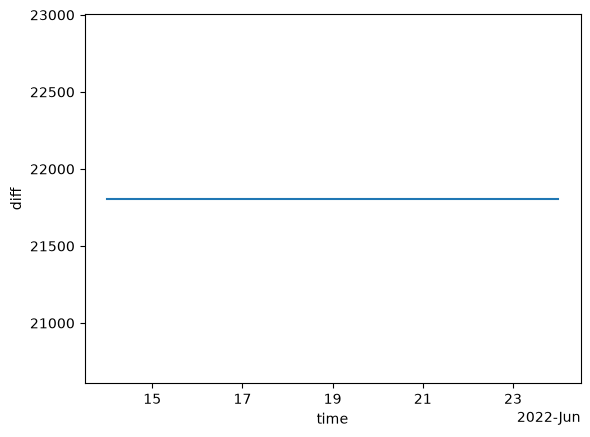

In [18]:
%%time
diff["diff"].count(["lat", "lon"]).plot()

In [19]:
%%time
diff.to_zarr(
    f"{target_root}/diff.zarr", mode="w", storage_options=storage_options, zarr_format=2
)

CPU times: user 13.3 ms, sys: 12.7 ms, total: 26 ms
Wall time: 31.9 ms


## 3. HEALPix regridding

In this step, we regrid the data from above to HEALPix coordinates. HEALPix (Hierarchical Equal Area isoLatitude Pixelization) is a spherical pixelation scheme that divides the sphere into equal-area pixels, eliminating spatial distortion [see the HEALPix documentation](https://healpix.sourceforge.io/).

This is a complex process, composed of several steps such as defining the HEALPix grid, creating the target grid and computing interpolation weights

Fortunately though, `pangeo-fish` embarks high-level functions to do the work for us!

In [20]:
from pangeo_fish.helpers import (
    open_diff_dataset,
    regrid_dataset_hpresample,
)

In [21]:
# Open the previous dataset (only necessary if you resume the notebook from here)
diff = open_diff_dataset(target_root=target_root, storage_options=storage_options)
diff

<xarray.Dataset> Size: 6MB
Dimensions:     (yi: 157, xi: 193, time: 11)
Coordinates:
    latitude    (yi, xi) float32 121kB 46.0 46.0 46.0 46.0 ... 59.0 59.0 59.0
    longitude   (yi, xi) float32 121kB -14.0 -13.92 -13.83 ... 1.833 1.917 2.0
  * time        (time) datetime64[ns] 88B 2022-06-14 2022-06-15 ... 2022-06-24
Dimensions without coordinates: yi, xi
Data variables:
    H0          (yi, xi) float32 121kB dask.array<chunksize=(157, 193), meta=np.ndarray>
    XE          (time, yi, xi) float64 3MB dask.array<chunksize=(6, 79, 193), meta=np.ndarray>
    diff        (time, yi, xi) float64 3MB dask.array<chunksize=(6, 79, 97), meta=np.ndarray>
    ocean_mask  (yi, xi) bool 30kB dask.array<chunksize=(157, 193), meta=np.ndarray>
Attributes:
    acoustic_tag_id:           OPI-372
    comment:                   pangeo-fish == 2026.5.1.dev39+g3d0455b93, heal...
    common_name:               Pollock
    history:                   {'Conventions': 'CF-1.4', 'bulletin_date': '20...
    pit_tag_id:                A19124
    project:                   FISHINTEL
    relative_depth_threshold:  0
    scientific_name:           Pollachius pollachius
    tag_name:                  A19124

In [22]:
reshaped, resampling_info = regrid_dataset_hpresample(
    ds=diff, refinement_level=refinement_level, min_vertices=min_vertices, dims=dims
)
reshaped

[KNeighborsResampler] dropping 2,943 retained cell(s) that passed the wide-neighbourhood 'threshold' test but were never selected by any sample's own Npt-nearest search (would otherwise silently read back as 0.0 for any input).
ocean_mask_final min/max : 0.0 1.0000000000000004


/Users/todaka/micromamba/envs/pangeo-fish-venv/lib/python3.11/site-packages/healpix_resample/bilinear.py:79: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:823.)
  M_coo = torch.sparse_coo_tensor(
/Users/todaka/micromamba/envs/pangeo-fish-venv/lib/python3.11/site-packages/healpix_resample/bilinear.py:120: UserWarning: Sparse CSR tensor support is in beta state. If you miss a functionality in the sparse tensor support, please submit a feature request to https://github.com/pytorch/pytorch/issues. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/SparseCsrTensorImpl.cpp:51.)
  self.M  = M_coo.to_sparse

[CloughTocherResampler] N=21807 samples, 43204 Delaunay triangles, K=32199 output cells retained (inside convex hull).
cellules océan non couvertes par Clough-Tocher : 576
cellules océan couvertes ni par CT ni par le repli : 240
H0 ('yi', 'xi')
XE ('time', 'yi', 'xi')
diff ('time', 'yi', 'xi')
ocean_mask ('yi', 'xi')


<xarray.Dataset> Size: 9MB
Dimensions:     (cells: 39388, time: 11)
Coordinates:
    cell_ids    (cells) int64 315kB 703347 703349 703350 ... 3662851 3662856
    latitude    (cells) float64 315kB 45.93 45.98 45.98 ... 59.01 59.06 59.06
    longitude   (cells) float64 315kB 1.004 1.101 1.005 ... 347.2 347.3 347.2
  * time        (time) datetime64[ns] 88B 2022-06-14 2022-06-15 ... 2022-06-24
    resolution  float64 8B 0.0009993
Dimensions without coordinates: cells
Data variables:
    ocean_mask  (cells) float64 315kB nan nan nan nan nan ... 1.0 1.0 1.0 1.0
    H0          (cells) float64 315kB nan nan nan nan ... 1.455e+03 478.0 482.5
    XE          (time, cells) float64 3MB nan nan nan ... -0.4775 -0.4795
    diff        (time, cells) float64 3MB nan nan nan nan ... 1.92 1.957 1.97
Attributes:
    acoustic_tag_id:           OPI-372
    comment:                   pangeo-fish == 2026.5.1.dev39+g3d0455b93, heal...
    common_name:               Pollock
    history:                   {'Conventions': 'CF-1.4', 'bulletin_date': '20...
    pit_tag_id:                A19124
    project:                   FISHINTEL
    relative_depth_threshold:  0
    scientific_name:           Pollachius pollachius
    tag_name:                  A19124
    grid_type:                 healpix
    level:                     10
    nside:                     1024

In [23]:
resampling_info["bbox"] = bbox
import json

# à enregistrer sous target root, doit contenir refinement level (non déjà sur combined), bbox, résolution de départ (xi,yi), ellipsoid
with open(f"{target_root}/resampling_info.json", "w") as f:
    json.dump(resampling_info, f)

with open(f"{target_root}/resampling_info.json") as f:
    resampling_info = json.load(f)
resampling_info

{'resolution_2D': [157, 193],
 'refinement_level': 10,
 'ellipsoid': 'sphere',
 'bbox': {'latitude': [46, 59], 'longitude': [-14, 2]}}

Let's plot the same chart as before to check that the HEALPix regridding hasn't changed the data

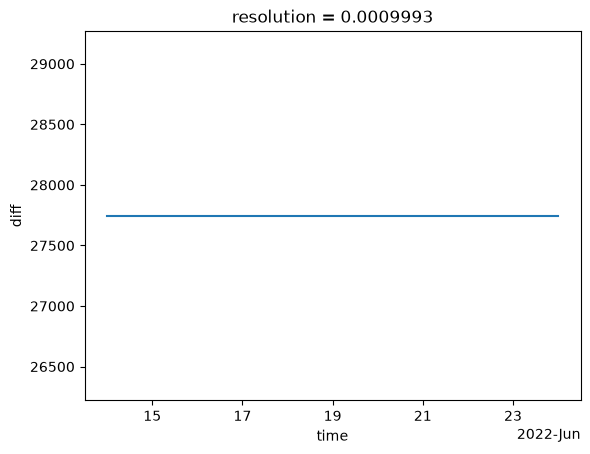

In [24]:
reshaped["diff"].count(dims).plot()

In [25]:
# Saves the result
reshaped.chunk(default_chunk_dims).to_zarr(
    f"{target_root}/diff-regridded.zarr",
    mode="w",
    consolidated=True,
    compute=True,
    storage_options=storage_options,
    zarr_format=2,
)

If you want to see the diff, you may have to install ipleaflet and ipwidget and some other extensions (they don't have compatibility problem and will be asked)

In [26]:
reshaped.healpix.plot(
    var="diff", refinement_level=refinement_level, alpha=0.8, ellipsoid=ellipsoid
)

## 4. Compute the emission probability distribution

In this step, we use the comparison result from the step above to construct the emission probability matrix.

This comparison is essentially he differences between the temperature measured by the tag and the reference sea temperature. 

The emission probability matrix represents the likelihood of observing a specific temperature difference given the model parameters and configurations.

In [27]:
from pangeo_fish.helpers import compute_emission_pdf

In [28]:
# Open the previous dataset (only necessary if you resume the notebook from here)
differences = xr.open_dataset(
    f"{target_root}/diff-regridded.zarr",
    engine="zarr",
    chunks={},
    storage_options=storage_options,
)

# ... and compute the emission matrices
emission_pdf = compute_emission_pdf(
    diff_ds=differences,
    events_ds=tag["tagging_events"].ds,
    differences_std=differences_std,
    initial_std=initial_std,
    recapture_std=recapture_std,
    dims=dims,
    chunk_time=chunk_time,
)[0]
emission_pdf

<xarray.Dataset> Size: 5MB
Dimensions:     (cells: 39388, time: 11)
Coordinates:
  * cell_ids    (cells) int64 315kB 703347 703349 703350 ... 3662851 3662856
    latitude    (cells) float64 315kB dask.array<chunksize=(39388,), meta=np.ndarray>
    longitude   (cells) float64 315kB dask.array<chunksize=(39388,), meta=np.ndarray>
    resolution  float64 8B ...
  * time        (time) datetime64[ns] 88B 2022-06-14 2022-06-15 ... 2022-06-24
Dimensions without coordinates: cells
Data variables:
    pdf         (time, cells) float64 3MB dask.array<chunksize=(1, 39388), meta=np.ndarray>
    initial     (cells) float64 315kB dask.array<chunksize=(39388,), meta=np.ndarray>
    final       (cells) float64 315kB dask.array<chunksize=(39388,), meta=np.ndarray>
    mask        (cells) float64 315kB dask.array<chunksize=(39388,), meta=np.ndarray>
Indexes:
    cell_ids  HealpixIndex(level=10, indexing_scheme=nested, kind=pandas)
Attributes: (12/15)
    acoustic_tag_id:           OPI-372
    comment:                   pangeo-fish == 2026.5.1.dev39+g3d0455b93, heal...
    common_name:               Pollock
    grid_type:                 healpix
    history:                   {'Conventions': 'CF-1.4', 'bulletin_date': '20...
    level:                     10
    ...                        ...
    relative_depth_threshold:  0
    scientific_name:           Pollachius pollachius
    tag_name:                  A19124
    differences_std:           0.75
    recapture_std:             0.0001
    initial_std:               1e-05

If you want to see the pdf

In [29]:
emission_pdf.healpix.plot("pdf", refinement_level, ellipsoid=ellipsoid)

Whatever the temporal distribution looks like, they must **never** (i.e, at _any time step_) sum to 0.

How could we check that visually? You'd have guessed it by now: similarly as before!

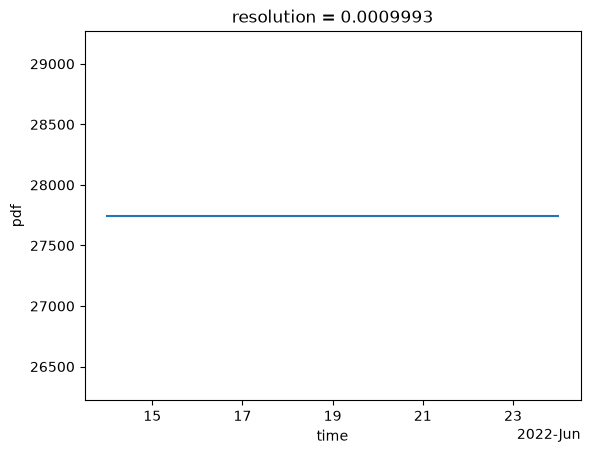

In [30]:
emission_pdf = emission_pdf.chunk(default_chunk_dims).persist()
emission_pdf["pdf"].count(dims).plot()

In [31]:
# Save the dataset
emission_pdf.to_zarr(
    f"{target_root}/emission_diff.zarr",
    mode="w",
    consolidated=True,
    storage_options=storage_options,
    zarr_format=2,
)

In [32]:
emission_pdf.attrs["sources"] = emission_pdf.attrs.get("sources", []) + [
    "temperature"
]  # this line allows to keep in memory what pdf had been calculated so far
emission_pdf.to_zarr(
    f"{target_root}/total_pdf.zarr",
    mode="w",
    consolidated=True,
    storage_options=storage_options,
    zarr_format=2,
)

## 5. Compute a 2nd _pdf_ with the acoustic detections

In this step, the goal is to calculate another emission distribution, this time from the acoustic detections.
**As such, it requires the tag to include at least one detection.**

These additional probabilities will enhance the emission _pdf_ constructed in the previous step by incorporating information from acoustic telemetry.

_NB: we will merge and normalize the two pdfs in the next stage of the workflow._

In [33]:
from pangeo_fish.helpers import compute_acoustic_pdf

In [34]:
# Load the previous emission pdf and compute the emission probabilities based on acoustic detections
emission_diff = xr.open_dataset(
    f"{target_root}/emission_diff.zarr",
    engine="zarr",
    chunks={},
    storage_options=storage_options,
)
acoustic_pdf = compute_acoustic_pdf(
    emission_ds=emission_diff,
    tag=tag,
    receiver_buffer=receiver_buffer,
    chunk_time=chunk_time,
    dims=dims,
)[0]
acoustic_pdf = acoustic_pdf.persist()
acoustic_pdf

<xarray.Dataset> Size: 4MB
Dimensions:     (cells: 39388, time: 11)
Coordinates:
    longitude   (cells) float64 315kB 1.004 1.101 1.005 ... 347.2 347.3 347.2
    latitude    (cells) float64 315kB 45.93 45.98 45.98 ... 59.01 59.06 59.06
    resolution  float64 8B 0.0009993
  * time        (time) datetime64[ns] 88B 2022-06-14 2022-06-15 ... 2022-06-24
  * cell_ids    (cells) int64 315kB 703347 703349 703350 ... 3662851 3662856
Dimensions without coordinates: cells
Data variables:
    acoustic    (time, cells) float64 3MB dask.array<chunksize=(1, 39388), meta=np.ndarray>
Indexes:
    cell_ids  HealpixIndex(level=10, indexing_scheme=nested, kind=pandas)
Attributes: (12/16)
    acoustic_tag_id:           OPI-372
    comment:                   pangeo-fish == 2026.5.1.dev39+g3d0455b93, heal...
    common_name:               Pollock
    differences_std:           0.75
    grid_type:                 healpix
    history:                   {'Conventions': 'CF-1.4', 'bulletin_date': '20...
    ...                        ...
    project:                   FISHINTEL
    recapture_std:             0.0001
    relative_depth_threshold:  0
    scientific_name:           Pollachius pollachius
    tag_name:                  A19124
    receiver_buffer:           1000 meter

If you wonder how this emission matrix looks like, you can plot a combined plot of the detections and the probabilities:

In [35]:
tag["acoustic"]["deployment_id"].hvplot.scatter(c="red", marker="x") * (
    acoustic_pdf["acoustic"] != 0
).sum(dim=dims).hvplot()

:Overlay
   .Scatter.I :Scatter   [time]   (deployment_id)
   .Curve.I   :Curve   [time]   (acoustic)

### Explanations
On the plot above, at detection times the number of counted values drop to a few value (`5` in this example).

These numbers correspond to the number of pixels that covers the detection area.

Therefore, such drop is expected, since at those times we know that the fish was detected around the acoustic receivers, and so it **can't** be elsewhere.

These sporadic detections will constraint a lot the geolocation model upon optimizing!

**The next cell is optional. It will save the acoustic emission distribution. It is not necessary (see the next step).**

In [36]:
acoustic_pdf.to_zarr(
    f"{target_root}/acoustic.zarr",
    mode="w",
    consolidated=True,
    storage_options=storage_options,
)

#### Merging

In [37]:
## ouvrir le total actuel
current_total = xr.open_dataset(
    f"{target_root}/total_pdf.zarr",
    engine="zarr",
    chunks={},
    storage_options=storage_options,
)
current_total

<xarray.Dataset> Size: 5MB
Dimensions:     (cells: 39388, time: 11)
Coordinates:
    cell_ids    (cells) int64 315kB dask.array<chunksize=(19694,), meta=np.ndarray>
    latitude    (cells) float64 315kB dask.array<chunksize=(39388,), meta=np.ndarray>
    longitude   (cells) float64 315kB dask.array<chunksize=(39388,), meta=np.ndarray>
    resolution  float64 8B ...
  * time        (time) datetime64[ns] 88B 2022-06-14 2022-06-15 ... 2022-06-24
Dimensions without coordinates: cells
Data variables:
    final       (cells) float64 315kB dask.array<chunksize=(39388,), meta=np.ndarray>
    initial     (cells) float64 315kB dask.array<chunksize=(39388,), meta=np.ndarray>
    mask        (cells) float64 315kB dask.array<chunksize=(39388,), meta=np.ndarray>
    pdf         (time, cells) float64 3MB dask.array<chunksize=(1, 39388), meta=np.ndarray>
Attributes: (12/16)
    acoustic_tag_id:           OPI-372
    comment:                   pangeo-fish == 2026.5.1.dev39+g3d0455b93, heal...
    common_name:               Pollock
    differences_std:           0.75
    grid_type:                 healpix
    history:                   {'Conventions': 'CF-1.4', 'bulletin_date': '20...
    ...                        ...
    project:                   FISHINTEL
    recapture_std:             0.0001
    relative_depth_threshold:  0
    scientific_name:           Pollachius pollachius
    sources:                   ['temperature']
    tag_name:                  A19124

In [38]:
if "acoustic" in current_total.data_vars:
    pass
else:
    current_total = current_total.load()
    current_total.attrs["sources"] = current_total.attrs.get("sources", []) + [
        "acoustic"
    ]

    merged_pdf = current_total.merge(
        acoustic_pdf.drop_indexes(["cell_ids"]), compat="override"
    )

    merged_pdf.to_zarr(
        f"{target_root}/total_pdf.zarr",
        mode="w",
        consolidated=True,
        storage_options=storage_options,
        zarr_format=2,
    )
merged_pdf

<xarray.Dataset> Size: 9MB
Dimensions:     (cells: 39388, time: 11)
Coordinates:
    cell_ids    (cells) int64 315kB 703347 703349 703350 ... 3662851 3662856
    latitude    (cells) float64 315kB 45.93 45.98 45.98 ... 59.01 59.06 59.06
    longitude   (cells) float64 315kB 1.004 1.101 1.005 ... 347.2 347.3 347.2
    resolution  float64 8B 0.0009993
  * time        (time) datetime64[ns] 88B 2022-06-14 2022-06-15 ... 2022-06-24
Dimensions without coordinates: cells
Data variables:
    final       (cells) float64 315kB 0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0
    initial     (cells) float64 315kB 0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0
    mask        (cells) float64 315kB nan nan nan nan nan ... 1.0 1.0 1.0 1.0
    pdf         (time, cells) float64 3MB nan nan nan ... 0.01767 0.01687
    acoustic    (time, cells) float64 3MB dask.array<chunksize=(1, 39388), meta=np.ndarray>
Attributes: (12/16)
    acoustic_tag_id:           OPI-372
    comment:                   pangeo-fish == 2026.5.1.dev39+g3d0455b93, heal...
    common_name:               Pollock
    differences_std:           0.75
    grid_type:                 healpix
    history:                   {'Conventions': 'CF-1.4', 'bulletin_date': '20...
    ...                        ...
    project:                   FISHINTEL
    recapture_std:             0.0001
    relative_depth_threshold:  0
    scientific_name:           Pollachius pollachius
    sources:                   ['temperature', 'acoustic']
    tag_name:                  A19124

## 6. Combine and normalize the X distributions

The normalization ensures that the probabilities sum up to one for each time step. 

In [39]:
from pangeo_fish.helpers import combine_pdfs
from pangeo_fish.helpers import normalize_pdf

In [40]:
current_total = xr.open_dataset(
    f"{target_root}/total_pdf.zarr",
    engine="zarr",
    chunks={},
    storage_options=storage_options,
)
current_total

<xarray.Dataset> Size: 9MB
Dimensions:     (time: 11, cells: 39388)
Coordinates:
    cell_ids    (cells) int64 315kB dask.array<chunksize=(19694,), meta=np.ndarray>
    latitude    (cells) float64 315kB dask.array<chunksize=(39388,), meta=np.ndarray>
    longitude   (cells) float64 315kB dask.array<chunksize=(39388,), meta=np.ndarray>
    resolution  float64 8B ...
  * time        (time) datetime64[ns] 88B 2022-06-14 2022-06-15 ... 2022-06-24
Dimensions without coordinates: cells
Data variables:
    acoustic    (time, cells) float64 3MB dask.array<chunksize=(1, 39388), meta=np.ndarray>
    final       (cells) float64 315kB dask.array<chunksize=(39388,), meta=np.ndarray>
    initial     (cells) float64 315kB dask.array<chunksize=(39388,), meta=np.ndarray>
    mask        (cells) float64 315kB dask.array<chunksize=(39388,), meta=np.ndarray>
    pdf         (time, cells) float64 3MB dask.array<chunksize=(1, 39388), meta=np.ndarray>
Attributes: (12/16)
    acoustic_tag_id:           OPI-372
    comment:                   pangeo-fish == 2026.5.1.dev39+g3d0455b93, heal...
    common_name:               Pollock
    differences_std:           0.75
    grid_type:                 healpix
    history:                   {'Conventions': 'CF-1.4', 'bulletin_date': '20...
    ...                        ...
    project:                   FISHINTEL
    recapture_std:             0.0001
    relative_depth_threshold:  0
    scientific_name:           Pollachius pollachius
    sources:                   ['temperature', 'acoustic']
    tag_name:                  A19124

In [41]:
emission_pdf = normalize_pdf(
    ds=current_total,
    chunks=default_chunk_dims,
    dims=dims,
    exclude=("initial", "final", "mask"),
    excluded_pdf=None,  # ("acoustic",)
)[0]

emission_pdf.to_zarr(
    f"{target_root}/combined.zarr",
    mode="w",
    consolidated=True,
    storage_options=storage_options,
    zarr_format=2,
)
combined = emission_pdf

(
    emission_pdf.sum(dims).hvplot(
        width=500, ylim=(0, 2), title="Sum of the probabilities"
    )
    + emission_pdf.count(dims).hvplot(
        width=500, title="Number of none-zero probabilities"
    )
).opts(shared_axes=False)

/Users/todaka/micromamba/envs/pangeo-fish-venv/lib/python3.11/site-packages/pangeo_fish/helpers.py:1387: UserWarning: you decided to normalize the pdf without: None, if you want to include them, change excluded_pdf 
  warnings.warn(


:Layout
   .NdOverlay.I  :NdOverlay   [Variable]
      :Curve   [time]   (value)
   .NdOverlay.II :NdOverlay   [Variable]
      :Curve   [time]   (value)

_The sums should equal to `1`._

In [42]:
combined.healpix.plot("pdf", refinement_level=refinement_level, ellipsoid=ellipsoid)

## 7. Estimate the model's parameters

It is now time to determine the parameters of the model based on the normalized emission matrix.

Precisely, is consists of finding the best `sigma`, which corresponds to the standard deviation of the Brownian motion that models the fish's movement between the time steps.  

To do so, in the following we:
1. Define the lower and upper bounds for `sigma`.  
2. Search for the best `sigma` with `optimize_pdf()`.
3. Save the results of the search (i.e., ` sigma`), along with any additional parameters used during the optimization, a human-readable `.json` file.

_NB: the search is a bounded 1D minimisation (Brent's method) between `1e-4` rad and `max_sigma = maximum_speed * time_step * adjustment_factor / earth_radius`. The cost function is not guaranteed to have a single minimum: for a short tag with weak temperature constraints (such as `A19124`, 11 days), a second valley appears at large `sigma`. Keep `adjustment_factor` small (1 here) so that the upper bound stays physically meaningful, and check the printed `f(x)` column: it should decrease and vary between iterations. If you want to compare with other values of `sigma`, see the last section of this notebook._


In [43]:
from pangeo_fish.helpers import optimize_pdf

In [44]:
# Open the distributions
emission = xr.open_dataset(
    f"{target_root}/combined.zarr",
    engine="zarr",
    chunks=default_chunk_dims,
    inline_array=True,
    storage_options=storage_options,
)
emission

<xarray.Dataset> Size: 5MB
Dimensions:     (cells: 39388, time: 11)
Coordinates:
    cell_ids    (cells) int64 315kB dask.array<chunksize=(39388,), meta=np.ndarray>
    latitude    (cells) float64 315kB dask.array<chunksize=(39388,), meta=np.ndarray>
    longitude   (cells) float64 315kB dask.array<chunksize=(39388,), meta=np.ndarray>
    resolution  float64 8B ...
  * time        (time) datetime64[ns] 88B 2022-06-14 2022-06-15 ... 2022-06-24
Dimensions without coordinates: cells
Data variables:
    final       (cells) float64 315kB dask.array<chunksize=(39388,), meta=np.ndarray>
    initial     (cells) float64 315kB dask.array<chunksize=(39388,), meta=np.ndarray>
    mask        (cells) float64 315kB dask.array<chunksize=(39388,), meta=np.ndarray>
    pdf         (time, cells) float64 3MB dask.array<chunksize=(1, 39388), meta=np.ndarray>
Attributes: (12/16)
    acoustic_tag_id:           OPI-372
    comment:                   pangeo-fish == 2026.5.1.dev39+g3d0455b93, heal...
    common_name:               Pollock
    differences_std:           0.75
    grid_type:                 healpix
    history:                   {'Conventions': 'CF-1.4', 'bulletin_date': '20...
    ...                        ...
    project:                   FISHINTEL
    recapture_std:             0.0001
    relative_depth_threshold:  0
    scientific_name:           Pollachius pollachius
    sources:                   ['temperature', 'acoustic']
    tag_name:                  A19124

In [45]:
# Define the parameter's bounds and search for the best value
params = optimize_pdf(
    ds=emission,
    earth_radius=earth_radius,
    adjustment_factor=adjustment_factor,
    truncate=truncate,
    maximum_speed=maximum_speed,
    tolerance=tolerance,
    dims=dims,
    # the results can be directly saved
    save_parameters=True,
    storage_options=storage_options,
    target_root=f"{target_root}",
    conv_method="LargeHealpixConv",  # fast multi-resolution convolution; "HealpixConv" is the slower reference method
)
params

 
 Func-count     x          f(x)          Procedure
    1     0.00365903      106.983        initial
    2     0.00585864      107.056        golden
    3      0.0022996      104.322        golden
    4     0.00145943       103.38        golden
    5    0.000401854       116.14        parabolic
    6     0.00105547      104.036        golden
    7     0.00162529      103.463        parabolic
    8     0.00147526      103.384        parabolic
    9     0.00138437      103.376        parabolic
   10     0.00125874       103.46        golden
   11     0.00141247      103.374        parabolic
   12     0.00141344      103.374        parabolic
   13     0.00141213      103.374        parabolic
   14      0.0014118      103.374        parabolic

Optimization terminated successfully;
The returned value satisfies the termination criteria
(using xtol =  1e-06 )


/Users/todaka/micromamba/envs/pangeo-fish-venv/lib/python3.11/site-packages/healpix_analyse/down.py:467: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:823.)
  M = torch.sparse_coo_tensor(
/Users/todaka/micromamba/envs/pangeo-fish-venv/lib/python3.11/site-packages/pangeo_fish/hmm/prediction.py:282: RuntimeWarning: sigma demandé (3.66e-03 rad) est inférieur ou égal au flou intrinsèque du Down/Up (4.87e-03 rad) pour cette géométrie. Le noyau compact sera quasi ponctuel, le flou effectif sera dominé par le Down/Up et ne pourra pas être réduit davantage.
  warnings.warn(


({'sigma': [0.0014121326945640952],
  'predictors': None,
  'predictor_factory': {'class': "<class 'pangeo_fish.hmm.prediction.UpDownGaussian1DHealpix'>",
   'kwargs': {'grid_info': "HealpixInfo(level=10, ellipsoid=None, indexing_scheme='nested')",
    'sigma': 'None',
    'kernel_sz': 'None',
    'max_compact_kernel_sz': '7',
    'device': 'cpu',
    'dtype': 'torch.float32'}},
  'comment': 'pangeo-fish == 2026.5.1.dev39+g3d0455b93, healpix-convolution == 0.1.2, xarray == 2025.3.1, xhealpixify == 2025.3.3'},
 <xarray.Dataset> Size: 5MB
 Dimensions:     (cells: 39388, time: 11)
 Coordinates:
   * cell_ids    (cells) int64 315kB 703347 703349 703350 ... 3662851 3662856
     latitude    (cells) float64 315kB 45.93 45.98 45.98 ... 59.01 59.06 59.06
     longitude   (cells) float64 315kB 1.004 1.101 1.005 ... 347.2 347.3 347.2
     resolution  float64 8B 0.0009993
   * time        (time) datetime64[ns] 88B 2022-06-14 2022-06-15 ... 2022-06-24
 Dimensions without coordinates: cells
 Data va

## 8. State probabilities and Trajectories

In this second to last step, we calculate the spatial probability distribution (based on the `sigma` found earlier) and further compute trajectories.

_NB: the computation precisely relies on `sigma` and the combined emission pdf._

In [ ]:
from pangeo_fish.helpers import predict_positions

In [ ]:
states, trajectories = predict_positions(
    target_root=f"{target_root}",
    storage_options=storage_options,
    chunks=default_chunk_dims,
    track_modes=track_modes,
    additional_track_quantities=additional_track_quantities,
    save=True,
)

Let's quickly check that the positional probability distribution `states` never sums to 0 for all timesteps!

In [ ]:
(
    states.sum(dims).hvplot(width=500, ylim=(0, 2), title="Sum of the probabilities")
    + states.count(dims).hvplot(width=500, title="Number of none-zero probabilities")
).opts(shared_axes=False)

## 9. Visualization

In this final step, we visualize various aspects of the analysis results to gain insights and interpret the model outcomes. 

We plot the emission distribution, which represents the likelihood of observing a specific temperature difference given the model parameters and configurations. 

Additionally, we visualize the state probabilities, showing the likelihood of the system (i.e, the fish) being in different states (i.e, positions) at each time step. 

We also plot the trajectories decoded before (if you saved them).

They display the possible movement patterns over time. 

Finally, we render the emission matrix and state probabilities in a video and store it.

### 9.1 Plotting the trajectories 

In [ ]:
from pangeo_fish.helpers import plot_trajectories

plot_trajectories(
    target_root=f"{target_root}",
    track_modes=track_modes,
    storage_options=storage_options,
    save_html=True,
)

### 9.2 Plotting the `states` and `emission` distributions 

In [ ]:
from pangeo_fish.helpers import open_distributions, render_distributions

In [ ]:
data = open_distributions(
    target_root=target_root,
    storage_options=storage_options,
    chunks=default_chunk_dims,
    chunk_time=chunk_time,
)
data

The interactive plot above is too large to be stored as a `HMTL` file (as done earlier with the trajectories).

Fortunately, `pangeo-fish` can efficiently render images of `data` and build a video from them! 

In [ ]:
%pip install imageio[ffmpeg]

In [ ]:
import numpy as np

lon = data["longitude"].values  # (nx,)
lat = data["latitude"].values  # (ny,)
lon_2d, lat_2d = np.meshgrid(lon, lat)  # (ny, nx), même construction qu'avant

data_2d = data.rename({"latitude": "y", "longitude": "x"})
data_2d = data_2d.assign_coords(
    longitude=(("y", "x"), lon_2d),
    latitude=(("y", "x"), lat_2d),
)
data_2d

In [ ]:
video_filename = render_distributions(
    data=data_2d,
    output_path=f"{target_root}/states",
    xlim=bbox["longitude"],
    ylim=bbox["latitude"],
    time_step=time_step,
    extension="mp4",
    frames_dir="images",
    remove_frames=True,
    storage_options=storage_options,
)

## ANNEXE. Impose the model's multiparameter
If you don't have the time or if you want to try other values of sigma\
Use `create_parameter` to set a value of sigma, you can also set different value of sigma in a single tag.\
If you want to test different sigma and compare the result create different folders like in the following cells.
And you can select another convolution method.

In [ ]:
import json
import warnings
from pathlib import Path
import fsspec
from pangeo_fish.helpers import create_parameters, test_parameter
from pangeo_fish.helpers import optimize_pdf

First create the folder


In [ ]:
# Open the distributions
emission = xr.open_dataset(
    f"{target_root}/combined.zarr",
    engine="zarr",
    chunks=default_chunk_dims,
    inline_array=True,
    storage_options=storage_options,
)
# Create a new folder
emission.to_zarr(
    f"{target_root}/hand_sigma/combined.zarr",  # replace "hand_sigma" by another name
    mode="w",
    consolidated=True,
    storage_options=storage_options,
    zarr_format=2,
)

Then add the parameter


In [ ]:
params = create_parameters(
    sigma=[0.002708796991645453],
    sigma_indices=None,
    class_name="UpDownGaussian1DHealpix",  # chose a method you can put something wrong to se them all
    target_root=f"{target_root}/hand_sigma",  # stay consistent here
    save_parameters=True,
)

You can go faster using `test_parameter`. This function do the same as the three cells above. You can put an emission you opened in `emission = None ` or let it at None. If you let it at None it will open the combined pdf which was created in chapter 6.


In [ ]:
params = test_parameter(
    emission=None,
    sigma_tested=[0.001],
    sigma_indices=None,
    Conv_method="UpDownGaussian1DHealpix",
    target_root=target_root,
    saving_root="/hand_sigma_UDG1D",
    default_chunk_dims=default_chunk_dims,
    storage_options=storage_options,
)

In [ ]:
from pangeo_fish.helpers import predict_positions

states_list = [
    predict_positions(
        target_root=f"{target_root}/{subfolder}",
        storage_options=storage_options,
        chunks=default_chunk_dims,
        track_modes=track_modes,
        additional_track_quantities=additional_track_quantities,
        save=True,
    )[0]
    for subfolder in [
        "",
        "hand_sigma",
        "hand_sigma_UDG1D",
    ]
]

If you want to compare the states


In [ ]:
from pangeo_fish.helpers import multi_map_with_synced_sliders, multiplot_healpix

liste = multiplot_healpix(
    [
        (states_list[0], ["states"]),
        (states_list[1], ["states"]),
        (states_list[2], ["states"]),
    ],
    refinement_level=refinement_level,
)
liste

multi_map_with_synced_sliders(liste)

In [ ]:
from pangeo_fish.helpers import plot_trajectories

traj_plots = [
    plot_trajectories(
        target_root=f"{target_root}/{subfolder}",
        track_modes=track_modes,
        storage_options=storage_options,
        save_html=True,
    ).options(title=f"Model's Folder: {subfolder}")
    for subfolder in [
        "",
        "hand_sigma",
        "hand_sigma_UDG1D",
    ]
]
(traj_plots[0] + traj_plots[1] + traj_plots[2]).cols(2)